In [1]:

import pandas as pd

file_path = "/content/wdbc.data"

df = pd.read_csv(file_path, header=None)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (569, 32)

First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:

import pandas as pd

# Column names from the Breast Cancer Wisconsin dataset
columns = [
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"
]

df = pd.read_csv("/content/wdbc.data", header=None, names=columns)

print("Dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())
print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (569, 32)

Missing values: 0

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

First 5 rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features (X) and target (y)
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Number of input features:", X_train_scaled.shape[1])
print("\nData preparation completed successfully!")


Training samples: 455
Testing samples: 114
Number of input features: 30

Data preparation completed successfully!


In [4]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build the neural network
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:

from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the neural network
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("\nModel training completed!")
print("Epochs completed:", len(history.history["loss"]))


Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.7500 - loss: 0.5826 - val_accuracy: 0.9670 - val_loss: 0.4010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9313 - loss: 0.3474 - val_accuracy: 0.9670 - val_loss: 0.2564
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9313 - loss: 0.2370 - val_accuracy: 0.9670 - val_loss: 0.1899
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9478 - loss: 0.1738 - val_accuracy: 0.9670 - val_loss: 0.1575
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9478 - loss: 0.1450 - val_accuracy: 0.9560 - val_loss: 0.1384
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9725 - loss: 0.1214 - val_accuracy: 0.9560 - val_loss: 0.1252
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9670 - loss: 0.1140 - val_accuracy: 0.9560 - val_loss: 0.1163
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9808 - loss: 0.0957 - val_accuracy: 0.956

In [6]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Predict probabilities on unseen test data
y_prob = model.predict(X_test_scaled)

# Convert probabilities into class labels
y_pred = (y_prob.ravel() >= 0.5).astype(int)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Benign (B)", "Malignant (M)"],
    zero_division=0
))


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step
Accuracy: 0.9912
Precision: 1.0
Recall: 0.9762
F1-score: 0.988

Confusion Matrix:
[[72  0]
 [ 1 41]]

Classification Report:
               precision    recall  f1-score   support

   Benign (B)       0.99      1.00      0.99        72
Malignant (M)       1.00      0.98      0.99        42

     accuracy                           0.99       114
    macro avg       0.99      0.99      0.99       114
 weighted avg       0.99      0.99      0.99       114



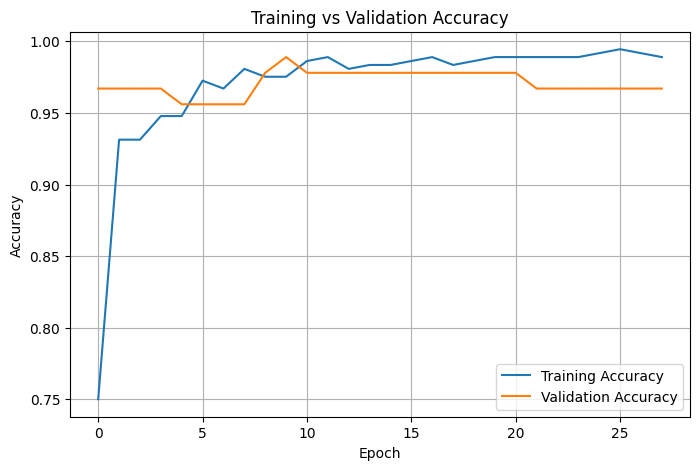

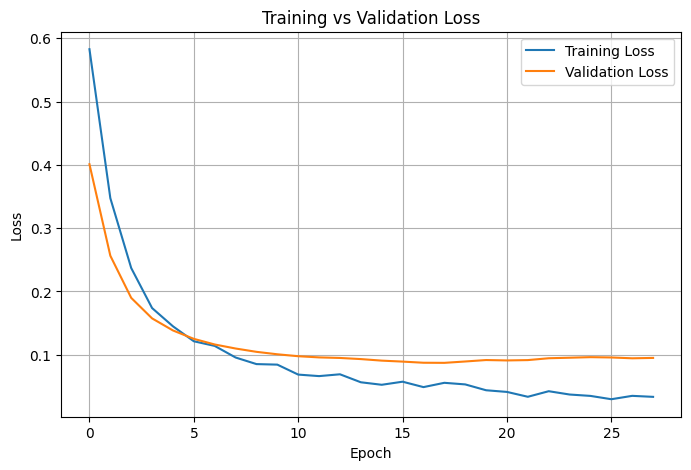

In [7]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


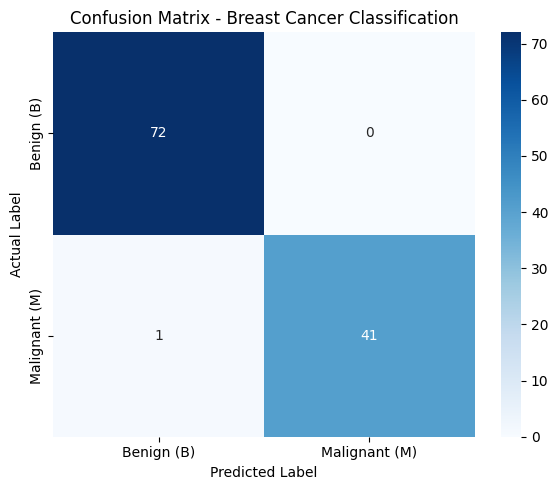

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Visualize the results
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign (B)", "Malignant (M)"],
    yticklabels=["Benign (B)", "Malignant (M)"]
)

plt.title("Confusion Matrix - Breast Cancer Classification")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


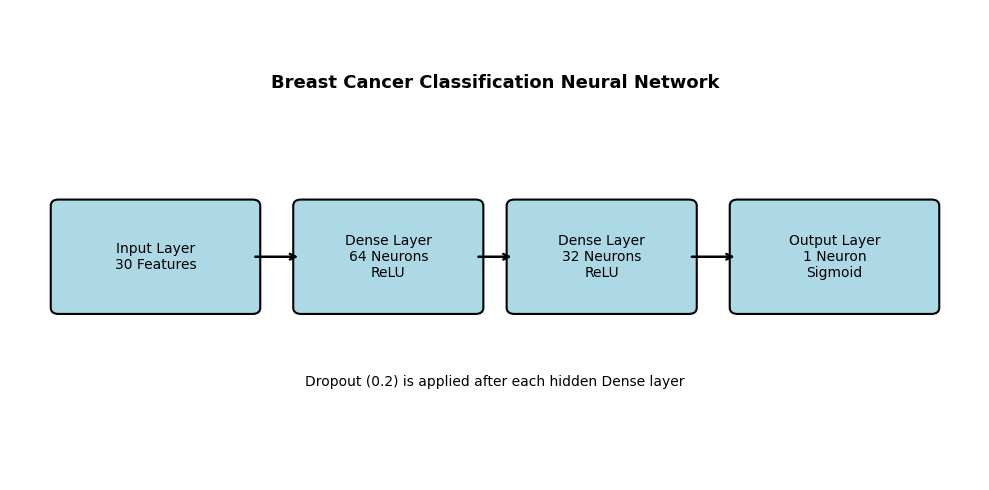

In [9]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Neural network architecture diagram
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

layers = [
    (0.5, 2.2, 2.0, 1.3, "Input Layer\n30 Features"),
    (3.0, 2.2, 1.8, 1.3, "Dense Layer\n64 Neurons\nReLU"),
    (5.2, 2.2, 1.8, 1.3, "Dense Layer\n32 Neurons\nReLU"),
    (7.5, 2.2, 2.0, 1.3, "Output Layer\n1 Neuron\nSigmoid")
]

for x, y, w, h, label in layers:
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        edgecolor="black",
        facecolor="lightblue",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x + w/2, y + h/2, label,
            ha="center", va="center", fontsize=10)

# Arrows between layers
for start, end in [(2.5, 3.0), (4.8, 5.2), (7.0, 7.5)]:
    ax.annotate(
        "", xy=(end, 2.85), xytext=(start, 2.85),
        arrowprops=dict(arrowstyle="->", linewidth=1.8)
    )

ax.text(5, 5.0, "Breast Cancer Classification Neural Network",
        ha="center", fontsize=13, fontweight="bold")
ax.text(5, 1.2, "Dropout (0.2) is applied after each hidden Dense layer",
        ha="center", fontsize=10)

plt.tight_layout()
plt.show()


In [10]:

import json
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Save the trained model
model.save("breast_cancer_model.keras")

# Save the feature scaler
import joblib
joblib.dump(scaler, "feature_scaler.pkl")

# Collect actual evaluation results
results = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, zero_division=0)),
    "training_epochs": len(history.history["loss"])
}

# Save results as a JSON file
with open("evaluation_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model and scaler saved successfully!")
print("\nFinal evaluation results:")
for metric, value in results.items():
    print(f"{metric}: {value}")



Model and scaler saved successfully!

Final evaluation results:
accuracy: 0.9912280701754386
precision: 1.0
recall: 0.9761904761904762
f1_score: 0.9879518072289156
training_epochs: 28


In [11]:

print("=" * 55)
print("BREAST CANCER CLASSIFICATION - PROJECT SUMMARY")
print("=" * 55)

print("\n1. Dataset Information")
print("Total samples:", len(df))
print("Total input features:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\n2. Neural Network Architecture")
model.summary()

print("\n3. Training Information")
print("Epochs completed:", len(history.history["loss"]))
print("Final training loss:", round(history.history["loss"][-1], 4))
print("Final training accuracy:", round(history.history["accuracy"][-1], 4))
print("Final validation loss:", round(history.history["val_loss"][-1], 4))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 4))

print("\n4. Test Evaluation")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\n5. Project Status: Evaluation completed")
print("=" * 55)


BREAST CANCER CLASSIFICATION - PROJECT SUMMARY

1. Dataset Information
Total samples: 569
Total input features: 30
Training samples: 455
Testing samples: 114

2. Neural Network Architecture


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,293 (48.02 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,196 (32.02 KB)


3. Training Information
Epochs completed: 28
Final training loss: 0.0336
Final training accuracy: 0.989
Final validation loss: 0.0951
Final validation accuracy: 0.967

4. Test Evaluation
Accuracy: 0.9912
Precision: 1.0
Recall: 0.9762
F1-score: 0.988

5. Project Status: Evaluation completed


In [12]:

import pandas as pd
import numpy as np

# Compare actual and predicted labels
comparison = pd.DataFrame({
    "Actual": y_test.map({0: "Benign", 1: "Malignant"}).values,
    "Predicted": pd.Series(y_pred, index=y_test.index)
        .map({0: "Benign", 1: "Malignant"}).values
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

print("Correct predictions:", comparison["Correct"].sum())
print("Incorrect predictions:", (~comparison["Correct"]).sum())

print("\nIncorrect predictions:")
display(comparison[comparison["Correct"] == False])

print("\nPrediction analysis completed.")


Correct predictions: 113
Incorrect predictions: 1

Incorrect predictions:


,Actual,Predicted,Correct
16,Malignant,Benign,False



Prediction analysis completed.


Final Training Accuracy: 0.989
Final Validation Accuracy: 0.967
Final Training Loss: 0.0336
Final Validation Loss: 0.0951

Training-Validation Accuracy Gap: 0.022
Validation-Training Loss Gap: 0.0615
Observation: No large final accuracy gap detected. Check both curves before concluding.


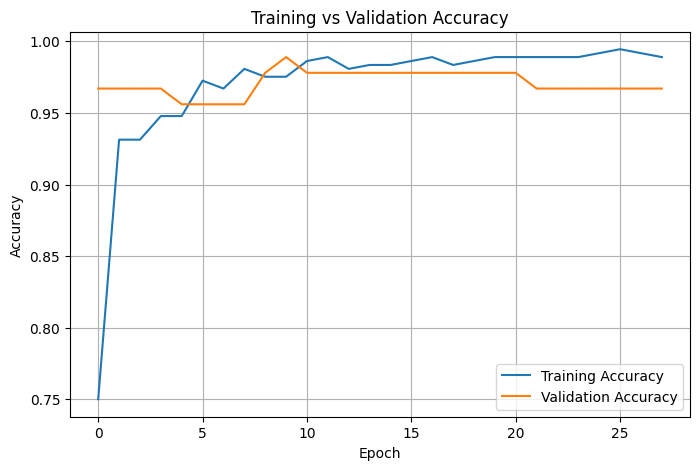

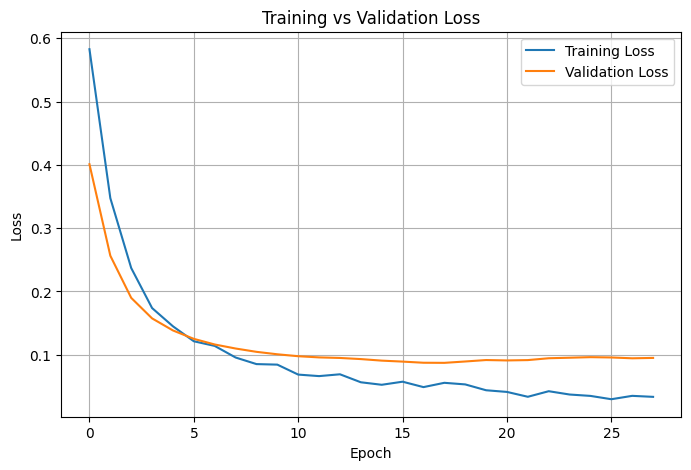

In [13]:
import matplotlib.pyplot as plt

# Get training and validation metrics
train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Final metrics
print("Final Training Accuracy:", round(train_acc[-1], 4))
print("Final Validation Accuracy:", round(val_acc[-1], 4))
print("Final Training Loss:", round(train_loss[-1], 4))
print("Final Validation Loss:", round(val_loss[-1], 4))

# Compare training and validation performance
accuracy_gap = train_acc[-1] - val_acc[-1]
loss_gap = val_loss[-1] - train_loss[-1]

print("\nTraining-Validation Accuracy Gap:", round(accuracy_gap, 4))
print("Validation-Training Loss Gap:", round(loss_gap, 4))

if accuracy_gap > 0.10 and loss_gap > 0:
    print("Observation: Possible overfitting. Training performance is better than validation performance.")
elif accuracy_gap > 0.05:
    print("Observation: There may be a moderate performance gap. Check the learning curves.")
else:
    print("Observation: No large final accuracy gap detected. Check both curves before concluding.")

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

MODEL EVALUATION RESULTS
-----------------------------------
Accuracy : 0.9912 (99.12%)
Precision: 1.0000
Recall   : 0.9762
F1-Score : 0.9880

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99        72
   Malignant       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



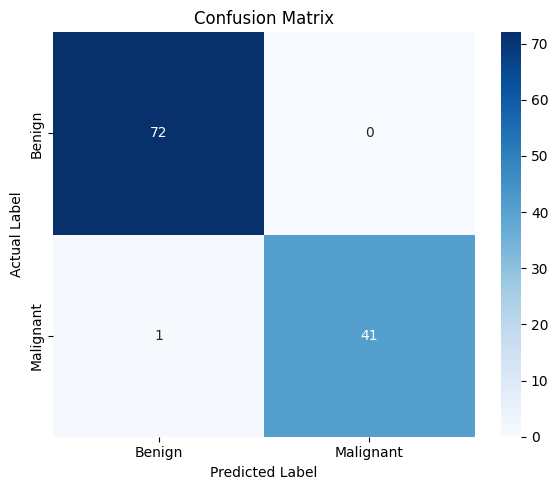

Metrics saved to final_evaluation_metrics.csv


In [14]:
# Step 14: Detailed Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display metrics
print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the metrics
results = pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1
}])

results.to_csv("final_evaluation_metrics.csv", index=False)
print("Metrics saved to final_evaluation_metrics.csv")

In [15]:
# Step 15: Save Final Project Summary

import json
import numpy as np

project_summary = {
    "project_title": "Breast Cancer Classification Using Deep Learning",
    "dataset": "Wisconsin Diagnostic Breast Cancer (WDBC)",
    "framework": "TensorFlow / Keras",
    "problem_type": "Binary Classification",
    "classes": {
        "0": "Benign",
        "1": "Malignant"
    },
    "total_samples": int(len(df)),
    "number_of_features": int(X.shape[1]),
    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),
    "model_architecture": [
        "Input layer: 30 features",
        "Dense layer: 64 neurons, ReLU",
        "Dropout: 0.2",
        "Dense layer: 32 neurons, ReLU",
        "Dropout: 0.2",
        "Output layer: 1 neuron, Sigmoid"
    ],
    "optimizer": "Adam",
    "loss_function": "Binary Crossentropy",
    "batch_size": 32,
    "maximum_epochs": 100,
    "epochs_completed": int(len(history.history["loss"])),
    "test_metrics": {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1)
    }
}

with open("final_project_summary.json", "w") as file:
    json.dump(project_summary, file, indent=4)

print("Final project summary saved successfully!")
print(json.dumps(project_summary, indent=4))

Final project summary saved successfully!
{
    "project_title": "Breast Cancer Classification Using Deep Learning",
    "dataset": "Wisconsin Diagnostic Breast Cancer (WDBC)",
    "framework": "TensorFlow / Keras",
    "problem_type": "Binary Classification",
    "classes": {
        "0": "Benign",
        "1": "Malignant"
    },
    "total_samples": 569,
    "number_of_features": 30,
    "training_samples": 455,
    "testing_samples": 114,
    "model_architecture": [
        "Input layer: 30 features",
        "Dense layer: 64 neurons, ReLU",
        "Dropout: 0.2",
        "Dense layer: 32 neurons, ReLU",
        "Dropout: 0.2",
        "Output layer: 1 neuron, Sigmoid"
    ],
    "optimizer": "Adam",
    "loss_function": "Binary Crossentropy",
    "batch_size": 32,
    "maximum_epochs": 100,
    "epochs_completed": 28,
    "test_metrics": {
        "accuracy": 0.9912280701754386,
        "precision": 1.0,
        "recall": 0.9761904761904762,
        "f1_score": 0.9879518072289156
